# This notebook explores the negative price data from the NEM.
# Runs the SQL code from negative_price_by_hour.sql to acquire the data in a tabular form
# Currently the data from load_prices.py covers 2024/01/01 to 2025/01/01 - Can load new data over a different range in that file.

In [ ]:
from pathlib import Path
import duckdb


ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

con = duckdb.connect(str(ROOT / "data" / "nem.duckdb"), read_only=True) # Connect to the database that was created
query = (ROOT / "sql" / "negative_price_by_hour.sql").read_text() # Turn the SQL query file into a text line for python to use
df = con.execute(query).df()
con.close()

df.head()

,region,hour,negative_proportion
0,NSW1,0,0.000000
1,NSW1,1,0.000228
2,NSW1,2,0.000000
3,NSW1,3,0.000683
4,NSW1,4,0.000228


# Acquired the table ordered by region and hour and the fraction of datapoints that had negative prices is recorded.
# Can calculate a percentage and show on a heatmap for region against hour.

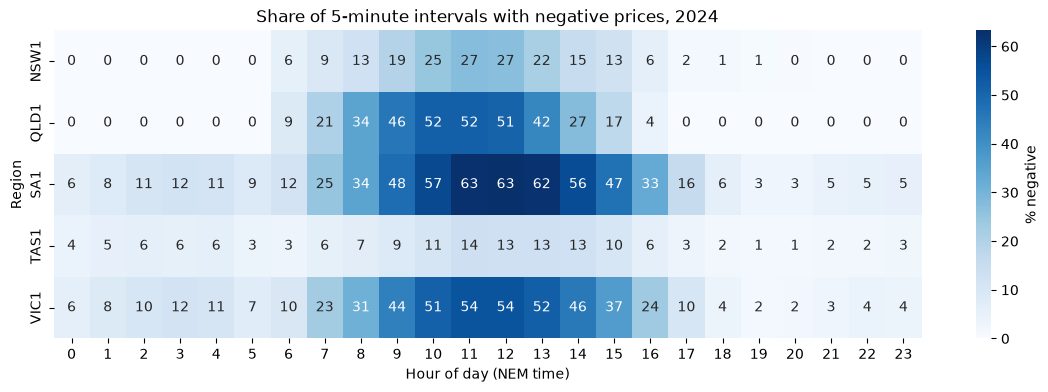

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# pivot the data so it's wide instead of long - one row for each region, then convert to percentage
pivot = df.pivot(index="region", columns="hour", values="negative_proportion") * 100

fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(
    pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    cbar_kws={"label": "% negative"},
    ax=ax,
)
ax.set_xlabel("Hour of day (NEM time)")
ax.set_ylabel("Region")
ax.set_title("Share of 5-minute intervals with negative prices, 2024")
plt.show()

fig.savefig(ROOT / "images" / "negative_by_hour_2024.png", dpi=150, bbox_inches="tight")

# Heatmap Analysis 
The above heatmap shows the percentage of negative prices among the five NEM regions across the whole year of 2024.
The data comes from the collection of 5-min intervals, so for example in SA 63% of 5-min intervals between 12pm and 1pm had a negative price.

## Observations
1. Periods for the peaks of negative prices show different behaviour between regions 
   - low proportions for TAS with max of 14% of intervals negative between 11am-12pm
   - NSW slightly larger with max of 27% between 11am-1pm
   - VIC and QLD have similar peak widths with maxima around 52-54% of negative prices between 10am-1pm
   - SA has the largest peak of around 60% of prices being negative between 10am-3pm
2. The periods themselves are not all consistently starting and ending at the same times - since the NEM timestamps use the same time, location with SA may be a factor where the sun peaks at different times.
3. VIC and SA have small peaks of up to 12% of prices negative very early in the morning between 1am and 5am. 

Can these observations be explained? 
Next step will be to research more about negative prices themselves - influence of solar power generation and location,
and to investigate at a higher granularity of the data.
This heatmap covers a single year and combines seasons - what does it look like separated by seasons? What about across multiple years?